# Can a Neural Network Solve This?
### Build the Brain — Post 3: Neural Networks

---

Look at this sequence:

```
┌─────┐  ┌─────┐  ┌─────┐  ┌─────┐  ┌─────┐
│ ●   │  │   ● │  │     │  │     │  │  ?  │
│     │  │     │  │     │  │     │  │     │
│     │  │     │  │   ● │  │ ●   │  │     │
└─────┘  └─────┘  └─────┘  └─────┘  └─────┘
 top-left  top-right  bot-right  bot-left   ???
```

The dot moves **clockwise**: top-left → top-right → bottom-right → bottom-left → top-left → ...

You solved that in 2 seconds. No rules. No code. Just pattern recognition.

**Now let's see if a neural network can learn to do the same thing — from scratch, with zero rules given.**

We're going to:
1. Generate training data (dot sequences)
2. Build a neural network from scratch (just numpy — no PyTorch, no TensorFlow)
3. Train it
4. Watch it learn to predict the next position
5. Visualise what it learned

No rules given. The network figures it out itself.

## Step 1 — Imports

Just numpy and matplotlib. No ML libraries. We're building this by hand so you can see every step.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

np.random.seed(42)
print("Ready.")

Ready.


## Step 2 — Represent the Problem as Numbers

Remember from Post 2: **everything is numbers**.

The dot has 4 possible positions:
- 0 = top-left
- 1 = top-right  
- 2 = bottom-right
- 3 = bottom-left

We use **one-hot encoding** to represent each position as a vector:
- top-left     → [1, 0, 0, 0]
- top-right    → [0, 1, 0, 0]
- bottom-right → [0, 0, 1, 0]
- bottom-left  → [0, 0, 0, 1]

The network sees the current position and must predict the next one.

In [ ]:
# Position names for display
POSITIONS = ["top-left", "top-right", "bottom-right", "bottom-left"]
COORDS = [(0.2, 0.75), (0.75, 0.75), (0.75, 0.25), (0.2, 0.25)]  # for visualisation


def one_hot(pos, n=4):
    """Convert position index to one-hot vector."""
    v = np.zeros(n)
    v[pos] = 1.0
    return v


def generate_sequence(n_samples=1000):
    """Generate (current_position, next_position) pairs.
    The rule: dot moves clockwise 0→1→2→3→0→...
    We NEVER tell the network this rule. It must discover it.
    """
    X, y = [], []
    # Start from random positions so the network can't cheat
    for _ in range(n_samples):
        current = np.random.randint(0, 4)
        next_pos = (current + 1) % 4  # clockwise rule
        X.append(one_hot(current))
        y.append(one_hot(next_pos))
    return np.array(X), np.array(y)


X_train, y_train = generate_sequence(1000)
X_test, y_test = generate_sequence(100)

print(f"Training samples: {X_train.shape}")
print(f"\nExample — current position: {POSITIONS[np.argmax(X_train[0])]}")
print(f"          correct next:     {POSITIONS[np.argmax(y_train[0])]}")
print(f"\nInput vector:  {X_train[0]}")
print(f"Output vector: {y_train[0]}")

Training samples: (1000, 4)

Example — current position: bottom-right
          correct next:     bottom-left

Input vector:  [0. 0. 1. 0.]
Output vector: [0. 0. 0. 1.]


Let's visualise the problem — what the network is learning.

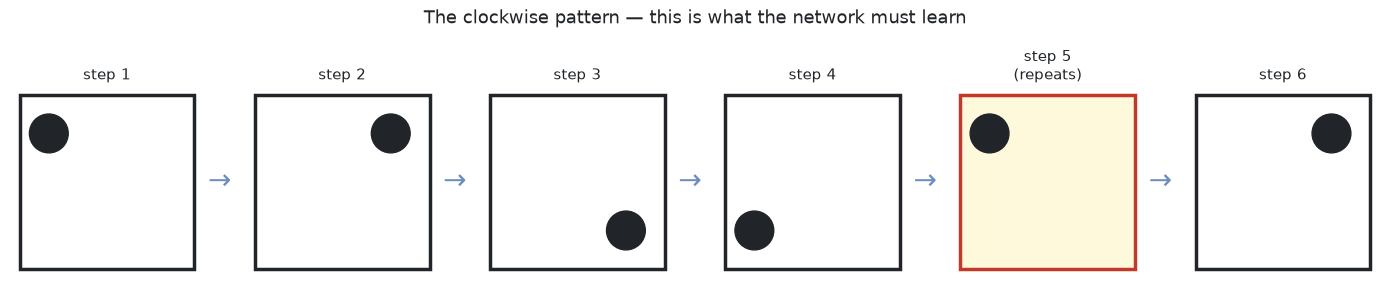

Rule: top-left(0) → top-right(1) → bottom-right(2) → bottom-left(3) → top-left(0) → ...
The network is NEVER told this rule. It learns it from examples.


In [ ]:
def draw_box(ax, dot_pos, title="", highlight=False):
    """Draw a box with a dot at the given position."""
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.axis("off")
    # Box
    rect = patches.Rectangle(
        (0.05, 0.05),
        0.9,
        0.9,
        linewidth=2.5,
        edgecolor="#C0392B" if highlight else "#212529",
        facecolor="#FFF9DB" if highlight else "white",
    )
    ax.add_patch(rect)
    # Dot
    cx, cy = COORDS[dot_pos]
    circle = plt.Circle((cx, cy), 0.1, color="#212529")
    ax.add_patch(circle)
    ax.set_title(title, fontsize=11, pad=4, color="#212529")


fig, axes = plt.subplots(1, 6, figsize=(14, 3))
fig.patch.set_facecolor("white")
sequence = [0, 1, 2, 3, 0, 1]  # clockwise
labels = ["step 1", "step 2", "step 3", "step 4", "step 5\n(repeats)", "step 6"]
for i, (pos, lbl) in enumerate(zip(sequence, labels)):
    draw_box(axes[i], pos, lbl, highlight=(i == 4))
    if i < 5:
        axes[i].annotate(
            "→",
            xy=(1.02, 0.5),
            xycoords="axes fraction",
            fontsize=20,
            ha="left",
            va="center",
            color="#6c8ebf",
        )

fig.suptitle(
    "The clockwise pattern — this is what the network must learn",
    fontsize=13,
    y=1.02,
    color="#212529",
)
plt.tight_layout()
plt.show()
print(
    "Rule: top-left(0) → top-right(1) → bottom-right(2) → bottom-left(3) → top-left(0) → ..."
)
print("The network is NEVER told this rule. It learns it from examples.")

## Step 3 — Build the Neural Network

A neural network has three things:

1. **Weights** — numbers that get adjusted during training (this is where the learned rules live)
2. **Forward pass** — input flows through layers, produces a prediction
3. **Backward pass (backpropagation)** — error flows backwards, weights get nudged

Our network:
```
Input (4)  →  Hidden layer (8 neurons)  →  Output (4)
```
- Input: one-hot current position [4 values]
- Hidden: 8 neurons that learn the internal representation
- Output: predicted next position [4 values, we pick the highest]

**Activation function: ReLU** — max(0, x). Keeps positive signals, kills negative ones. Simple and effective.

In [ ]:
class NeuralNetwork:
    def __init__(self, input_size=4, hidden_size=8, output_size=4, lr=0.1):
        self.lr = lr
        # Weights — initialised small random numbers
        # W1: connects input → hidden  (4 × 8)
        # W2: connects hidden → output (8 × 4)
        self.W1 = np.random.randn(input_size, hidden_size) * 0.1
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = np.random.randn(hidden_size, output_size) * 0.1
        self.b2 = np.zeros((1, output_size))
        self.loss_history = []

    def relu(self, x):
        return np.maximum(0, x)

    def relu_derivative(self, x):
        return (x > 0).astype(float)

    def softmax(self, x):
        # Convert raw scores to probabilities (all sum to 1)
        e = np.exp(x - np.max(x, axis=1, keepdims=True))
        return e / e.sum(axis=1, keepdims=True)

    def forward(self, X):
        # Input → Hidden
        self.z1 = X @ self.W1 + self.b1  # linear combination
        self.a1 = self.relu(self.z1)  # activation
        # Hidden → Output
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = self.softmax(self.z2)  # probabilities
        return self.a2

    def backward(self, X, y, output):
        n = X.shape[0]
        # How wrong were we?
        delta2 = output - y  # output error
        dW2 = self.a1.T @ delta2 / n
        db2 = delta2.mean(axis=0, keepdims=True)
        # Propagate error backwards through hidden layer
        delta1 = (delta2 @ self.W2.T) * self.relu_derivative(self.z1)
        dW1 = X.T @ delta1 / n
        db1 = delta1.mean(axis=0, keepdims=True)
        # Nudge weights in the right direction
        self.W2 -= self.lr * dW2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dW1
        self.b1 -= self.lr * db1

    def train(self, X, y, epochs=500):
        for epoch in range(epochs):
            output = self.forward(X)
            # Cross-entropy loss — how wrong is our prediction?
            loss = -np.mean(np.sum(y * np.log(output + 1e-8), axis=1))
            self.loss_history.append(loss)
            self.backward(X, y, output)
            if epoch % 100 == 0:
                acc = self.accuracy(X, y)
                print(
                    f"Epoch {epoch:4d} | Loss: {loss:.4f} | Accuracy: {acc * 100:.1f}%"
                )

    def predict(self, X):
        return np.argmax(self.forward(X), axis=1)

    def accuracy(self, X, y):
        return np.mean(self.predict(X) == np.argmax(y, axis=1))


print("Neural network defined.")
print("Architecture: 4 inputs → 8 hidden neurons (ReLU) → 4 outputs (Softmax)")
print("No rules given. Training starts with random weights.")

Neural network defined.
Architecture: 4 inputs → 8 hidden neurons (ReLU) → 4 outputs (Softmax)
No rules given. Training starts with random weights.


## Step 4 — Train It

Watch the accuracy go from ~25% (random guessing) to 100% as the network discovers the clockwise rule.

Each epoch:
- Network makes a prediction
- We measure how wrong it is (loss)
- Error travels backwards (backpropagation)
- Weights get nudged slightly
- Repeat

In [ ]:
nn = NeuralNetwork(input_size=4, hidden_size=8, output_size=4, lr=0.1)

print(
    f"Before training — Test accuracy: {nn.accuracy(X_test, y_test) * 100:.1f}%  (random = 25%)"
)
print("-" * 55)
nn.train(X_train, y_train, epochs=500)
print("-" * 55)
print(f"\nAfter training  — Test accuracy: {nn.accuracy(X_test, y_test) * 100:.1f}%")

Before training — Test accuracy: 26.0%  (random = 25%)
-------------------------------------------------------
Epoch    0 | Loss: 1.3883 | Accuracy: 23.0%
Epoch  100 | Loss: 0.6535 | Accuracy: 100.0%
Epoch  200 | Loss: 0.0820 | Accuracy: 100.0%
Epoch  300 | Loss: 0.0298 | Accuracy: 100.0%
Epoch  400 | Loss: 0.0167 | Accuracy: 100.0%
-------------------------------------------------------

After training  — Test accuracy: 100.0%


## Step 5 — Visualise the Learning

This is the learning curve — the network getting smarter over time.

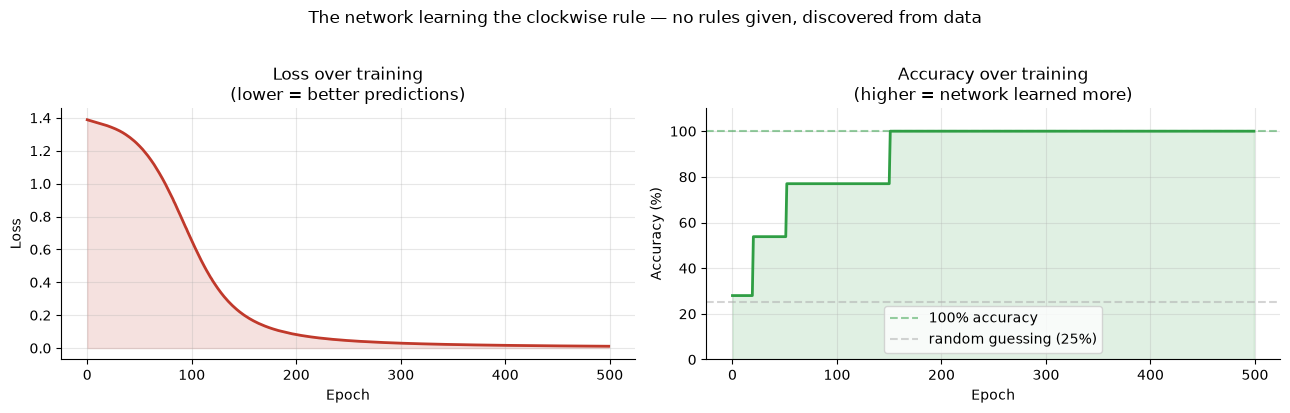

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.patch.set_facecolor("white")

# Loss curve
axes[0].plot(nn.loss_history, color="#C0392B", linewidth=2)
axes[0].fill_between(
    range(len(nn.loss_history)), nn.loss_history, alpha=0.15, color="#C0392B"
)
axes[0].set_title("Loss over training\n(lower = better predictions)", fontsize=12)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].grid(alpha=0.3)

# Accuracy over epochs — recalculate
nn2 = NeuralNetwork(input_size=4, hidden_size=8, output_size=4, lr=0.1)
acc_history = []
for _ in range(500):
    out = nn2.forward(X_train)
    acc_history.append(nn2.accuracy(X_train, y_train) * 100)
    nn2.backward(X_train, y_train, out)

axes[1].plot(acc_history, color="#2f9e44", linewidth=2)
axes[1].fill_between(range(len(acc_history)), acc_history, alpha=0.15, color="#2f9e44")
axes[1].axhline(
    y=100, color="#2f9e44", linestyle="--", alpha=0.5, label="100% accuracy"
)
axes[1].axhline(
    y=25, color="#aaaaaa", linestyle="--", alpha=0.5, label="random guessing (25%)"
)
axes[1].set_title(
    "Accuracy over training\n(higher = network learned more)", fontsize=12
)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_ylim(0, 110)
axes[1].legend(fontsize=10)
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].grid(alpha=0.3)

plt.suptitle(
    "The network learning the clockwise rule — no rules given, discovered from data",
    fontsize=12,
    y=1.02,
)
plt.tight_layout()
plt.show()

## Step 6 — Test It

Ask it the question from the blog post. Current position: bottom-left (3). What comes next?

In [8]:
print("=" * 50)
print("TESTING THE NETWORK")
print("=" * 50)

for current_pos in range(4):
    x = one_hot(current_pos).reshape(1, -1)
    probs = nn.forward(x)[0]
    predicted = np.argmax(probs)
    correct = (current_pos + 1) % 4
    status = "✓" if predicted == correct else "✗"

    print(f"\nCurrent:   {POSITIONS[current_pos]}")
    print(f"Predicted: {POSITIONS[predicted]}  {status}")
    print(f"Correct:   {POSITIONS[correct]}")
    print(f"Confidence scores: ", end="")
    for i, p in enumerate(probs):
        marker = " ← winner" if i == predicted else ""
        print(f"{POSITIONS[i]}: {p:.3f}{marker}", end="  ")
    print()

TESTING THE NETWORK

Current:   top-left
Predicted: top-right  ✓
Correct:   top-right
Confidence scores: top-left: 0.003  top-right: 0.991 ← winner  bottom-right: 0.001  bottom-left: 0.005  

Current:   top-right
Predicted: bottom-right  ✓
Correct:   bottom-right
Confidence scores: top-left: 0.002  top-right: 0.002  bottom-right: 0.989 ← winner  bottom-left: 0.007  

Current:   bottom-right
Predicted: bottom-left  ✓
Correct:   bottom-left
Confidence scores: top-left: 0.001  top-right: 0.010  bottom-right: 0.005  bottom-left: 0.985 ← winner  

Current:   bottom-left
Predicted: top-left  ✓
Correct:   top-left
Confidence scores: top-left: 0.990 ← winner  top-right: 0.005  bottom-right: 0.003  bottom-left: 0.001  


## Step 7 — Visualise the Predictions

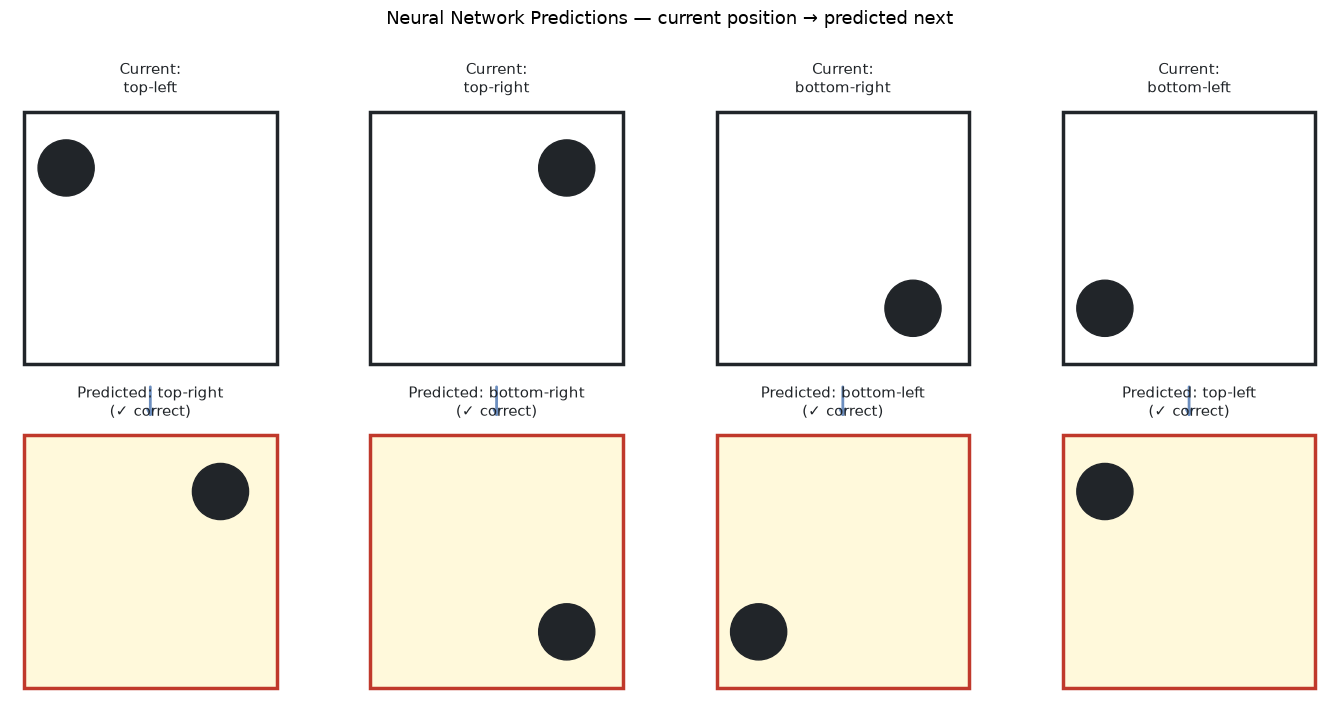

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
fig.patch.set_facecolor("white")
fig.suptitle(
    "Neural Network Predictions — current position → predicted next",
    fontsize=13,
    y=1.01,
)

for i in range(4):
    x = one_hot(i).reshape(1, -1)
    probs = nn.forward(x)[0]
    predicted = np.argmax(probs)
    correct = (i + 1) % 4

    # Top row: current
    draw_box(axes[0][i], i, f"Current:\n{POSITIONS[i]}")

    # Bottom row: predicted
    is_correct = predicted == correct
    draw_box(
        axes[1][i],
        predicted,
        f"Predicted: {POSITIONS[predicted]}\n({'✓ correct' if is_correct else '✗ wrong'})",
        highlight=is_correct,
    )

    # Arrow between rows
    axes[0][i].annotate(
        "",
        xy=(0.5, -0.15),
        xycoords="axes fraction",
        xytext=(0.5, -0.02),
        textcoords="axes fraction",
        arrowprops=dict(arrowstyle="->", color="#6c8ebf", lw=2),
    )

axes[0][0].set_ylabel("Input\n(current)", fontsize=11, labelpad=10)
axes[1][0].set_ylabel("Output\n(predicted next)", fontsize=11, labelpad=10)

plt.tight_layout()
plt.show()

## Step 8 — What Did It Actually Learn?

The rule is now stored in the weights. Let's peek inside.

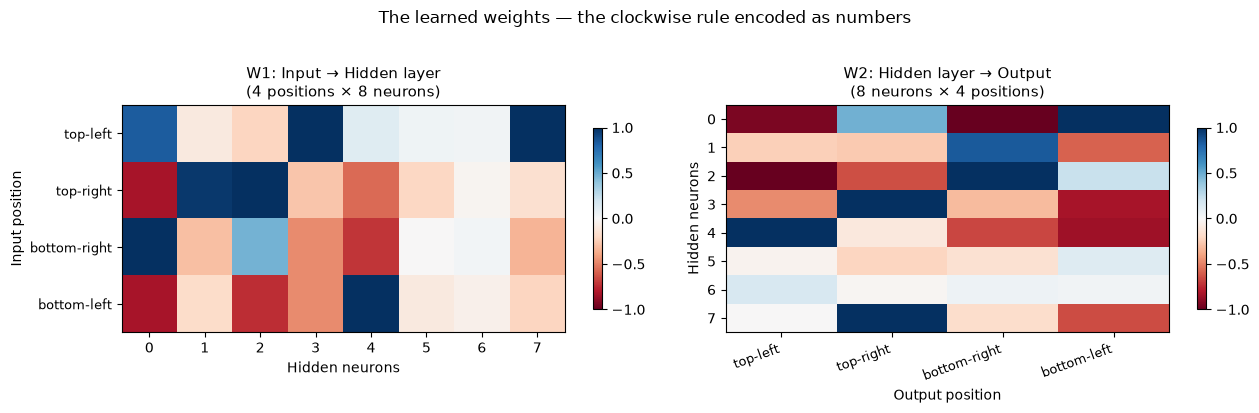

Red = strong positive weight (activates)
Blue = strong negative weight (suppresses)
The pattern in these numbers IS the clockwise rule — nobody wrote it.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.patch.set_facecolor("white")

# W1: input → hidden
im1 = axes[0].imshow(nn.W1, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
axes[0].set_title("W1: Input → Hidden layer\n(4 positions × 8 neurons)", fontsize=11)
axes[0].set_xlabel("Hidden neurons")
axes[0].set_ylabel("Input position")
axes[0].set_yticks(range(4))
axes[0].set_yticklabels(POSITIONS, fontsize=9)
plt.colorbar(im1, ax=axes[0], shrink=0.8)

# W2: hidden → output
im2 = axes[1].imshow(nn.W2, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
axes[1].set_title("W2: Hidden layer → Output\n(8 neurons × 4 positions)", fontsize=11)
axes[1].set_xlabel("Output position")
axes[1].set_ylabel("Hidden neurons")
axes[1].set_xticks(range(4))
axes[1].set_xticklabels(POSITIONS, rotation=20, ha="right", fontsize=9)
plt.colorbar(im2, ax=axes[1], shrink=0.8)

fig.suptitle(
    "The learned weights — the clockwise rule encoded as numbers", fontsize=12, y=1.02
)
plt.tight_layout()
plt.show()

print("Red = strong positive weight (activates)")
print("Blue = strong negative weight (suppresses)")
print("The pattern in these numbers IS the clockwise rule — nobody wrote it.")

## Bonus — What if we break the pattern?

The network learned **clockwise**. What happens if we give it a sequence that goes anti-clockwise? It'll get it wrong — because it only learned what it was trained on.

This is a key lesson: **a neural network is only as good as its training data.**

In [ ]:
print("What if the rule was ANTI-clockwise instead?")
print("Our network was trained on clockwise — let's see what happens.\n")

print(f"{'Current':<15} {'NN predicts':<18} {'Anti-clockwise correct':<22} {'Right?'}")
print("-" * 65)
for pos in range(4):
    x = one_hot(pos).reshape(1, -1)
    predicted = np.argmax(nn.forward(x))
    anti_clockwise_correct = (pos - 1) % 4
    right = "✓" if predicted == anti_clockwise_correct else "✗ (learned clockwise)"
    print(
        f"{POSITIONS[pos]:<15} {POSITIONS[predicted]:<18} {POSITIONS[anti_clockwise_correct]:<22} {right}"
    )

print("\nLesson: the network learned exactly what it was trained on.")
print("Change the training data → it learns a different rule.")
print("No rules were hardcoded. All rules came from data.")

What if the rule was ANTI-clockwise instead?
Our network was trained on clockwise — let's see what happens.

Current         NN predicts        Anti-clockwise correct Right?
-----------------------------------------------------------------
top-left        top-right          bottom-left            ✗ (learned clockwise)
top-right       bottom-right       top-left               ✗ (learned clockwise)
bottom-right    bottom-left        top-right              ✗ (learned clockwise)
bottom-left     top-left           bottom-right           ✗ (learned clockwise)

Lesson: the network learned exactly what it was trained on.
Change the training data → it learns a different rule.
No rules were hardcoded. All rules came from data.


## What just happened?

In ~500 lines of numpy, we built a network that:

1. **Started with random weights** — 25% accuracy (just guessing)
2. **Saw 1,000 examples** of (current position → next position)
3. **Adjusted its weights** via backpropagation after each batch
4. **Discovered the clockwise rule** — nobody told it
5. **Reached 100% accuracy** — predicts correctly every time

The rule `0 → 1 → 2 → 3 → 0` is now encoded as a pattern of positive and negative numbers in W1 and W2. That's it. That's a neural network.

---

**Now imagine instead of 4 positions, you have:**
- 50,000 word positions (a vocabulary)
- Billions of training examples (the internet)
- Hundreds of layers instead of 2
- Billions of weights instead of 64

That's an LLM. Same idea. Massively bigger.

---

*This notebook is part of **Build the Brain** — Post 3*  
*Series by Kavya Sree Kammari*